# Lab 3 — Maps of data: reduction and dimension

**Accompanies Lecture 4 (dimensionality reduction) and the first half of Lecture 5 (how many dimensions?).**

Every method that draws high-dimensional data in 2D keeps something and gives something up. In this lab you build the tools that show what.

| # | Exercise | What you build |
|---|---|---|
| 1 | The Earth and the double-centring test | distance matrices, `double_centre`, `classical_mds` |
| 2 | Isomap by hand | `geodesic_distances`, `isomap`, and a scan over $k$ |
| 3 | Audit your picture | `trustworthiness`, `continuity` |
| 4 | Is this cluster real? | `count_clusters`, `cluster_counts`, `is_persistent` |
| 5 | Dimension by counting (take-home) | `correlation_slope`, `median_mu`, `local_slopes` |

Every exercise ends with an `assert` cell. If your code is correct, the notebook runs from top to bottom with no error. Exercises 1–4 are for the lab session (Exercise 4 needs about a minute of computing), Exercise 5 can be finished at home.


In [1]:
import math, warnings
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import umap
from scipy.sparse.csgraph import shortest_path
from scipy.spatial import procrustes
from scipy.spatial.distance import cdist, pdist
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness as sk_trustworthiness
from sklearn.neighbors import NearestNeighbors, kneighbors_graph

warnings.filterwarnings("ignore")
assert tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 3), "scikit-learn >= 1.3 is needed for HDBSCAN"
NAVY, TEAL, AMBER, ICE = "#1E2761", "#1C7293", "#E8871E", "#CADCFC"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| umap-learn", umap.__version__)


numpy 1.26.4 | scikit-learn 1.3.2 | umap-learn 0.5.7


## Exercise 1 — The Earth and the double-centring test

From the lecture: a distance matrix $D$ comes from points in some Euclidean space **if and only if** $B=-\tfrac12\,J\,D^{(2)}J$ is positive semidefinite, where $D^{(2)}$ holds the squared distances and $J=I-\tfrac1n\mathbf 1\mathbf 1^T$. Classical MDS then reads coordinates off the top eigenvectors of $B$.

You write four functions:

1. `great_circle_distances(U)`: distance *along the surface*, $R\arccos(u\cdot v)$.
2. `chord_distances(U)`: straight line *through* the Earth, $R\,\|u-v\|$.
3. `double_centre(D)`: the matrix $B$ above.
4. `classical_mds(D, k)`: take the eigenvectors of $B$ for its $k$ largest eigenvalues, scaled by the square roots of the eigenvalues (set negative eigenvalues to $0$). Use `np.linalg.eigh`.


In [2]:
# GIVEN: 14 cities and their unit vectors on the sphere
cities = {"Warsaw": (52.23, 21.01), "Reykjavik": (64.15, -21.94), "Sydney": (-33.87, 151.21), "Lima": (-12.05, -77.04),
          "Tokyo": (35.68, 139.69), "Cape Town": (-33.92, 18.42), "New York": (40.71, -74.01), "Moscow": (55.76, 37.62),
          "Beijing": (39.90, 116.41), "Buenos Aires": (-34.60, -58.38), "Los Angeles": (34.05, -118.24), "Nairobi": (-1.29, 36.82),
          "Honolulu": (21.31, -157.86), "Singapore": (1.35, 103.82)}
names = list(cities)
latlon = np.array([cities[c] for c in names])

def unit_vectors(latlon_deg):
    lat, lon = np.radians(latlon_deg[:, 0]), np.radians(latlon_deg[:, 1])
    return np.column_stack([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)])

U = unit_vectors(latlon)
R = 6371.0   # km


In [3]:
# SOLUTION
def great_circle_distances(U, R=6371.0):
    return R * np.arccos(np.clip(U @ U.T, -1, 1))

def chord_distances(U, R=6371.0):
    return R * np.linalg.norm(U[:, None, :] - U[None, :, :], axis=-1)

def double_centre(D):
    n = len(D)
    J = np.eye(n) - np.ones((n, n)) / n
    return -0.5 * J @ (D ** 2) @ J

def classical_mds(D, k=2):
    w, V = np.linalg.eigh(double_centre(D))
    idx = np.argsort(w)[::-1][:k]
    return V[:, idx] * np.sqrt(np.maximum(w[idx], 0))


In [4]:
# GIVEN: look at the eigenvalues of B (in units of 10^6 km^2) and at the quality of a 2D map
Dg, Dc = great_circle_distances(U), chord_distances(U)

def eigen_summary(D):
    w = np.linalg.eigvalsh(double_centre(D))[::-1]
    return w, int((w > 1e4).sum()), int((w < -1e4).sum())

for label, D in [("chord distances", Dc), ("great-circle distances", Dg)]:
    w, npos, nneg = eigen_summary(D)
    print(f"{label:24s}: {npos} positive eigenvalues, {nneg} negative")

def map_quality(D, Y):
    """Median relative distance error of the map, and how many of each city's 3 nearest cities survive."""
    E = np.linalg.norm(Y[:, None] - Y[None], axis=-1); iu = np.triu_indices(len(D), 1)
    err = np.median(np.abs(E[iu] - D[iu]) / D[iu])
    def nn3(M):
        M = M.copy(); np.fill_diagonal(M, np.inf); return [set(np.argsort(M[i])[:3]) for i in range(len(M))]
    overlap = np.mean([len(a & b) for a, b in zip(nn3(D), nn3(E))])
    return float(err), float(overlap)

Y_map = classical_mds(Dg, 2)
err, overlap = map_quality(Dg, Y_map)
print(f"2D map by classical MDS: median distance error {100 * err:.1f} %, {overlap:.2f} of 3 nearest cities kept")

# MDS and PCA must agree on Euclidean points
rng = np.random.default_rng(0)
Xe = rng.normal(size=(60, 5)) @ rng.normal(size=(5, 5))
De = np.linalg.norm(Xe[:, None] - Xe[None], axis=-1)
diff = np.abs(np.abs(classical_mds(De, 3)) - np.abs(PCA(3).fit_transform(Xe))).max()
print(f"MDS vs PCA on Euclidean points: max coordinate difference {diff:.1e}")


chord distances         : 3 positive eigenvalues, 0 negative
great-circle distances  : 7 positive eigenvalues, 6 negative
2D map by classical MDS: median distance error 11.9 %, 2.07 of 3 nearest cities kept
MDS vs PCA on Euclidean points: max coordinate difference 1.1e-14


In [5]:
# CHECK
_, npos_c, nneg_c = eigen_summary(Dc)
_, npos_g, nneg_g = eigen_summary(Dg)
assert (npos_c, nneg_c) == (3, 0), "chord distances are Euclidean: exactly 3 positive and no negative eigenvalues"
assert nneg_g >= 1, "great-circle distances cannot be Euclidean: B must have negative eigenvalues"
assert (npos_g, nneg_g) == (7, 6), (npos_g, nneg_g)
assert diff < 1e-8, "classical MDS must equal PCA on Euclidean points"
assert 0.10 < err < 0.14 and 1.8 < overlap < 2.3, (err, overlap)
print("Exercise 1 passed.")


Exercise 1 passed.


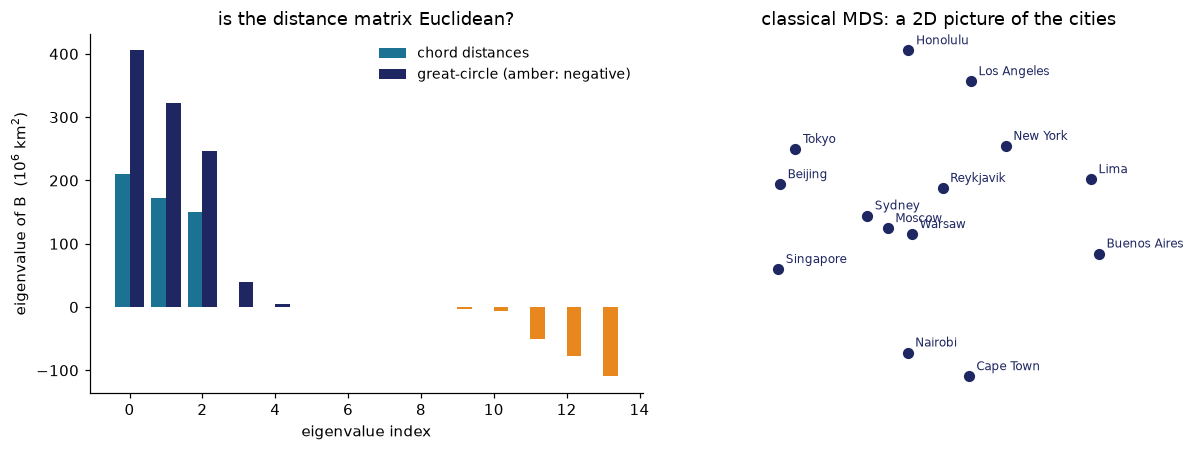

In [6]:
# GIVEN: the picture
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
wc, _, _ = eigen_summary(Dc); wg, _, _ = eigen_summary(Dg); x = np.arange(len(wg))
ax[0].bar(x - 0.2, wc / 1e6, 0.4, color=TEAL, label="chord distances")
ax[0].bar(x + 0.2, wg / 1e6, 0.4, color=[AMBER if v < 0 else NAVY for v in wg], label="great-circle (amber: negative)")
ax[0].set_xlabel("eigenvalue index"); ax[0].set_ylabel("eigenvalue of B  (10$^6$ km$^2$)"); ax[0].legend(frameon=False, fontsize=9)
ax[0].set_title("is the distance matrix Euclidean?")
ax[1].scatter(Y_map[:, 0], Y_map[:, 1], color=NAVY, s=40)
for i, nm in enumerate(names): ax[1].annotate(nm, Y_map[i], textcoords="offset points", xytext=(5, 4), fontsize=8, color=NAVY)
ax[1].set_aspect("equal"); ax[1].axis("off"); ax[1].set_title("classical MDS: a 2D picture of the cities")
plt.tight_layout(); plt.show()


*Discuss:* the chord matrix has exactly three non-zero eigenvalues. What does that say about the cities? The great-circle matrix has negative eigenvalues. What do they say about *every* flat map, and does it matter which method draws it?

## Exercise 2 — Isomap by hand

Isomap is three steps: (1) connect every point to its $k$ nearest neighbours, (2) take shortest-path distances in that graph as estimates of the geodesic distances, (3) run classical MDS on them. You already wrote step 3 in Exercise 1.

You write:

1. `geodesic_distances(X, k)`: build the graph with `kneighbors_graph(X, k, mode="distance")`, then `shortest_path(A, directed=False)`. The result may contain `inf` if the graph is disconnected.
2. `isomap(X, k)`: return `None` if any distance is infinite, otherwise the 2D MDS embedding of the geodesic distances.
3. The scan: for every $k$ in `ks`, store in `disparity[k]` the value `procrustes(truth, Y)[2]` (how far your picture is from the exact unrolled sheet; $0$ is perfect), or `None` if the graph is disconnected.

The Swiss roll is the sheet $(s,h)$ rolled up in 3D, and `truth` holds its exact unrolled coordinates.


In [7]:
# GIVEN: the Swiss roll and its exact unrolled coordinates (s, h), s = arc length along the spiral
rng = np.random.default_rng(0); n = 1500
t = rng.uniform(1.5 * np.pi, 4.5 * np.pi, n); h = rng.uniform(0, 14, n)
roll = np.column_stack([t * np.cos(t), h, t * np.sin(t)])
s = 0.5 * (t * np.sqrt(1 + t ** 2) + np.arcsinh(t))
truth = np.column_stack([s, h])
ks = [2, 3, 5, 10, 20, 40, 60, 100]


In [8]:
# SOLUTION
def geodesic_distances(X, k):
    A = kneighbors_graph(X, k, mode="distance")
    return shortest_path(A, directed=False)

def isomap(X, k):
    Dgeo = geodesic_distances(X, k)
    if np.isinf(Dgeo).any():
        return None
    return classical_mds(Dgeo, 2)

disparity = {}
for k in ks:
    Y = isomap(roll, k)
    disparity[k] = None if Y is None else float(procrustes(truth, Y)[2])


In [9]:
# GIVEN
for k in ks:
    print(f"k = {k:3d}:", "graph disconnected" if disparity[k] is None else f"disparity {disparity[k]:.4f}")
window = [k for k in ks if disparity[k] is not None and disparity[k] < 0.01]
print("working window:", window)


k =   2: graph disconnected
k =   3: graph disconnected
k =   5: disparity 0.0030
k =  10: disparity 0.0008
k =  20: disparity 0.0001
k =  40: disparity 0.5076
k =  60: disparity 0.9467
k = 100: disparity 0.9678
working window: [5, 10, 20]


In [10]:
# CHECK
assert disparity[2] is None, "with k = 2 the graph falls apart"
assert disparity[10] < 0.01, "k = 10 should unroll the sheet almost exactly"
assert disparity[60] > 0.3, "k = 60 should short-circuit the roll"
assert window == [5, 10, 20], window
print("Exercise 2 passed.")


Exercise 2 passed.


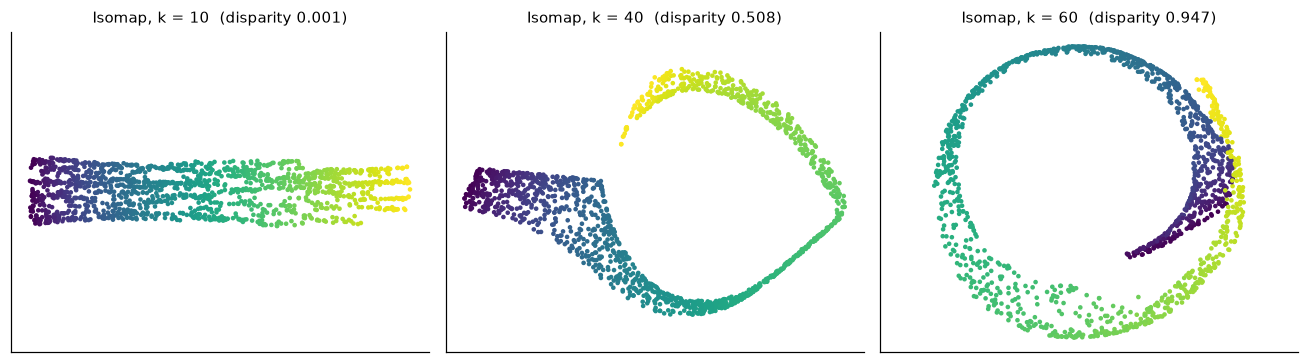

In [11]:
# GIVEN: the picture
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, k in zip(ax, (10, 40, 60)):
    Y = isomap(roll, k)
    a.scatter(Y[:, 0], Y[:, 1], c=t, cmap="viridis", s=4); a.set_title(f"Isomap, k = {k}  (disparity {disparity[k]:.3f})", fontsize=10)
    a.set_xticks([]); a.set_yticks([]); a.set_aspect("equal", adjustable="datalim")
plt.tight_layout(); plt.show()


*Discuss:* the working window is $k\approx5$ to $20$. Why does a small $k$ fail, and why does $k=40$ already fail? (Hint: compare the distance from a point to its $k$-th neighbour with the distance between two neighbouring turns of the roll.) Does this window remind you of anything from persistence?

## Exercise 3 — Audit your picture

A 2D picture can go wrong in two ways: **false gluing** (strangers end up adjacent) and **tears** (true neighbours end up far apart). From the lecture, with $k$ neighbours, ranks $r(i,j)$ in the data and $\hat r(i,j)$ in the picture:

$$T(k)=1-\frac{2}{nk(2n-3k-1)}\sum_i\sum_{j\in U_k(i)}\big(r(i,j)-k\big),$$

where $U_k(i)$ are the $k$ nearest neighbours of $i$ in the picture that are **not** among its $k$ nearest in the data (the intruders). Continuity $C(k)$ is the same with the roles of data and picture exchanged.

You write:

1. `trustworthiness(X, Y, k=10)`: straight from the formula. Hint: `rank = np.argsort(np.argsort(cdist(X, X), axis=1), axis=1)` gives rank $0$ to the point itself and rank $r$ to the $r$-th nearest neighbour; the picture's neighbours of $i$ are `np.argsort(cdist(Y, Y), axis=1)[i, 1:k+1]`.
2. `continuity(X, Y, k=10)`: one line, using the first function.

Then you audit PCA, t-SNE and UMAP on a sphere.


In [12]:
# GIVEN: 600 points on the sphere S^2
rng = np.random.default_rng(0)
v = rng.normal(size=(600, 3))
sphere = v / np.linalg.norm(v, axis=1, keepdims=True)


In [13]:
# SOLUTION
def trustworthiness(X, Y, k=10):
    n = len(X)
    rank_X = np.argsort(np.argsort(cdist(X, X), axis=1), axis=1)
    nn_Y = np.argsort(cdist(Y, Y), axis=1)[:, 1:k + 1]
    penalty = 0
    for i in range(n):
        for j in nn_Y[i]:
            if rank_X[i, j] > k:
                penalty += rank_X[i, j] - k
    return 1 - 2 / (n * k * (2 * n - 3 * k - 1)) * penalty

def continuity(X, Y, k=10):
    return trustworthiness(Y, X, k)


In [14]:
# CHECK 1 -- your functions against scikit-learn (this cell must run without error)
Y_pca = PCA(2).fit_transform(sphere)
assert abs(trustworthiness(sphere, Y_pca) - sk_trustworthiness(sphere, Y_pca, n_neighbors=10)) < 1e-9, "trustworthiness differs from scikit-learn"
assert abs(continuity(sphere, Y_pca) - sk_trustworthiness(Y_pca, sphere, n_neighbors=10)) < 1e-9, "continuity differs from scikit-learn"
print(f"PCA of the sphere: T = {trustworthiness(sphere, Y_pca):.6f}, C = {continuity(sphere, Y_pca):.6f}  (agrees with scikit-learn)")


PCA of the sphere: T = 0.855038, C = 0.990789  (agrees with scikit-learn)


In [15]:
# GIVEN: three 2D pictures of the same sphere, and their audit
pictures = {"PCA": Y_pca,
            "t-SNE": TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(sphere),
            "UMAP": umap.UMAP(n_neighbors=15, random_state=0).fit_transform(sphere)}
audit = {m: (trustworthiness(sphere, Y), continuity(sphere, Y)) for m, Y in pictures.items()}
print("          T      C     T - C")
for m, (Tm, Cm) in audit.items():
    print(f"{m:6s} {Tm:.3f}  {Cm:.3f}  {Tm - Cm:+.3f}")


          T      C     T - C
PCA    0.855  0.991  -0.136
t-SNE  0.999  0.981  +0.017
UMAP   0.998  0.987  +0.011


In [16]:
# CHECK 2
assert audit["PCA"][1] - audit["PCA"][0] > 0.1, "PCA keeps neighbours but glues strangers: C should exceed T clearly"
assert audit["t-SNE"][0] - audit["t-SNE"][1] > 0.005, "t-SNE keeps trust but tears the sphere: T should exceed C"
assert audit["UMAP"][0] - audit["UMAP"][1] > 0.005, "UMAP keeps trust but tears the sphere: T should exceed C"
print("Exercise 3 passed.")


Exercise 3 passed.


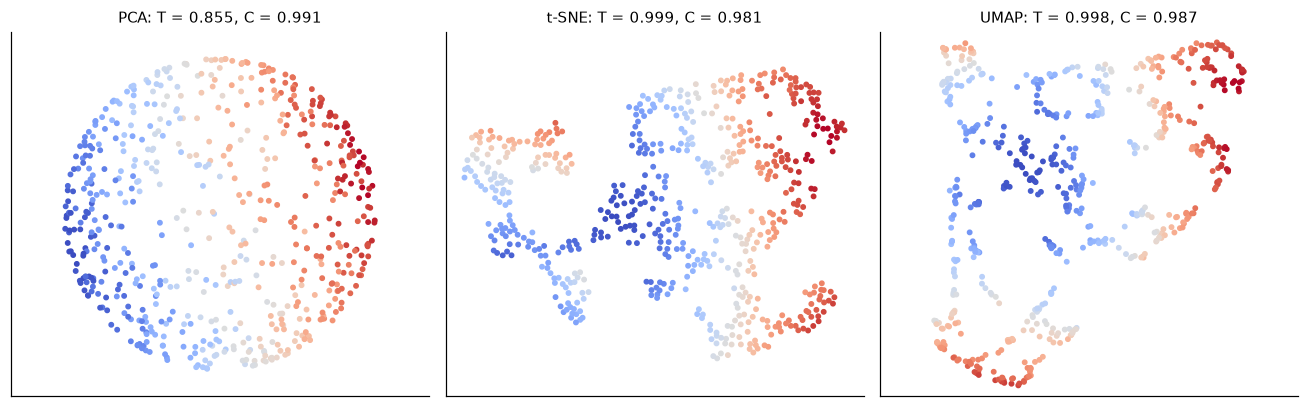

In [17]:
# GIVEN: the pictures, coloured by height (z) on the sphere: a tear shows as a colour jump
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
for a, (m, Y) in zip(ax, pictures.items()):
    a.scatter(Y[:, 0], Y[:, 1], c=sphere[:, 2], cmap="coolwarm", s=8)
    a.set_title(f"{m}: T = {audit[m][0]:.3f}, C = {audit[m][1]:.3f}", fontsize=10); a.set_xticks([]); a.set_yticks([]); a.set_aspect("equal", adjustable="datalim")
plt.tight_layout(); plt.show()


*Discuss:* there is no continuous injective map from the sphere to the plane (Borsuk–Ulam). How do the three rows of the table show the two ways of failing? Why would a method with $T=C=1$ be impossible here?

## Exercise 4 — Is this cluster real?

From the lecture: a cluster that exists for one parameter value only is not evidence. Here you test two data sets in 50 dimensions: **pure noise** (no structure) and **three true blobs**.

You write:

1. `count_clusters(Y)`: the number of clusters HDBSCAN (`min_cluster_size=15`) finds in the points `Y`. HDBSCAN labels unassigned points `-1`, so the count is `labels.max() + 1`.
2. `cluster_counts(X)`: for each setting in `grid`, embed `X` in 2D with the given `embed` function and count the clusters in the picture. Return the list of counts, in the order of `grid`.
3. `is_persistent(counts)`: `True` if the count is the same at every setting.

(The embeddings take about a minute in total.)


In [18]:
# GIVEN: two data sets, a parameter grid, and an embedding helper
rng = np.random.default_rng(1)
noise = rng.uniform(size=(600, 50))
centres = rng.normal(0, 6, size=(3, 50))
blobs = np.vstack([c + rng.normal(size=(200, 50)) for c in centres])

grid = [("tsne", 5), ("tsne", 30), ("tsne", 100), ("umap", 5), ("umap", 15), ("umap", 100)]

def embed(X, method, p, seed=0):
    if method == "tsne":
        return TSNE(2, perplexity=p, init="pca", random_state=seed).fit_transform(X)
    return umap.UMAP(n_neighbors=p, random_state=seed).fit_transform(X)


In [19]:
# SOLUTION
def count_clusters(Y):
    return int(HDBSCAN(min_cluster_size=15).fit_predict(Y).max() + 1)

def cluster_counts(X):
    return [count_clusters(embed(X, method, p)) for method, p in grid]

def is_persistent(counts):
    return len(set(counts)) == 1


In [20]:
# GIVEN
counts_noise, counts_blobs = cluster_counts(noise), cluster_counts(blobs)
print("clusters found in the ORIGINAL 50-d data:   noise", count_clusters(noise), "| blobs", count_clusters(blobs))
print("settings:", [f"{m}({p})" for m, p in grid])
print("noise  :", counts_noise, " persistent?", is_persistent(counts_noise))
print("blobs  :", counts_blobs, " persistent?", is_persistent(counts_blobs))


clusters found in the ORIGINAL 50-d data:   noise 0 | blobs 3
settings: ['tsne(5)', 'tsne(30)', 'tsne(100)', 'umap(5)', 'umap(15)', 'umap(100)']
noise  : [2, 0, 3, 2, 2, 2]  persistent? False
blobs  : [3, 3, 3, 3, 3, 3]  persistent? True


In [21]:
# CHECK
assert count_clusters(noise) == 0 and count_clusters(blobs) == 3
assert counts_blobs == [3] * 6, counts_blobs
assert not is_persistent(counts_noise), "the noise clusters change with the parameter"
assert is_persistent(counts_blobs) and not is_persistent([2, 0, 4])
print("Exercise 4 passed.")


Exercise 4 passed.


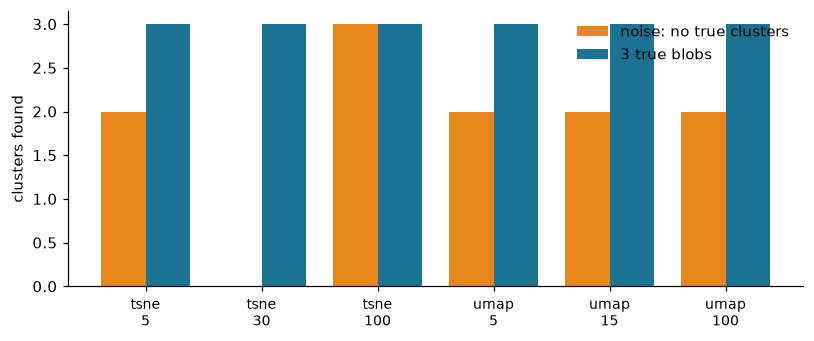

In [22]:
# GIVEN: the picture
fig, ax = plt.subplots(figsize=(7.5, 3.2))
xs = np.arange(len(grid)); w = 0.38
ax.bar(xs - w / 2, counts_noise, w, color=AMBER, label="noise: no true clusters")
ax.bar(xs + w / 2, counts_blobs, w, color=TEAL, label="3 true blobs")
ax.set_xticks(xs); ax.set_xticklabels([f"{m}\n{p}" for m, p in grid], fontsize=9); ax.set_ylabel("clusters found")
ax.legend(frameon=False); plt.tight_layout(); plt.show()


*Discuss:* both data sets produce clusters in some pictures. What distinguishes the real ones? Which of the rules from the lecture did `is_persistent` implement, and what would a second rule (a shuffled null, or a different seed) add?

## Exercise 5 — Dimension by counting (take-home)

If points are sampled from a $D$-dimensional manifold, the fraction $C(r)$ of pairs closer than $r$ grows like $r^D$. You write:

1. `correlation_slope(X, lo=0.005, hi=0.05, m=12)`: take the `lo` and `hi` quantiles of the pairwise distances (`pdist`), make `m` radii spaced geometrically between them (`np.geomspace`), compute $C(r)$ for each, and return the slope of $\log C$ against $\log r$ (`np.polyfit(..., 1)[0]`).
2. `median_mu(X)`: for every point the ratio $\mu=r_2/r_1$ of the distances to its second and first nearest neighbour (use `NearestNeighbors(n_neighbors=3)`; column 0 is the point itself); return the median of $\mu$. Observation from the lecture: it should be close to $2^{1/D}$.
3. `local_slopes(X, radii)`: the local slope of $\log C(r)$ against $\log r$ at every radius (`np.gradient(np.log(C), np.log(radii))`).


In [23]:
# GIVEN: sets of known dimension, and a "ball of yarn" (a circle of radius 1 with noise 0.03 in 3D)
def circle50(n, seed=0):
    th = np.random.default_rng(seed).uniform(0, 2 * np.pi, n); X = np.zeros((n, 50)); X[:, 0], X[:, 1] = np.cos(th), np.sin(th); return X
def sphere3(n, seed=0):
    v = np.random.default_rng(seed).normal(size=(n, 3)); return v / np.linalg.norm(v, axis=1, keepdims=True)
def cube(n, k, seed=0):
    return np.random.default_rng(seed).uniform(size=(n, k))
def yarn(n, seed=0):
    rng = np.random.default_rng(seed); th = rng.uniform(0, 2 * np.pi, n)
    return np.column_stack([np.cos(th), np.sin(th), 0 * th]) + 0.03 * rng.normal(size=(n, 3))

sets = {"circle in 50-d (D = 1)": circle50(3000), "sphere S2 (D = 2)": sphere3(3000), "5-cube (D = 5)": cube(3000, 5)}
radii = np.geomspace(0.006, 1.2, 30)


In [24]:
# SOLUTION
def correlation_slope(X, lo=0.005, hi=0.05, m=12):
    D = pdist(X)
    rs = np.geomspace(*np.quantile(D, [lo, hi]), m)
    C = np.array([(D <= r).mean() for r in rs])
    return float(np.polyfit(np.log(rs), np.log(C), 1)[0])

def median_mu(X):
    d, _ = NearestNeighbors(n_neighbors=3).fit(X).kneighbors(X)
    mu = d[:, 2] / d[:, 1]
    return float(np.median(mu[np.isfinite(mu)]))

def local_slopes(X, radii):
    D = pdist(X)
    C = np.array([(D <= r).mean() for r in radii])
    return np.gradient(np.log(C), np.log(radii))


In [25]:
# GIVEN
slopes = {name: correlation_slope(X) for name, X in sets.items()}
for name, v in slopes.items(): print(f"correlation slope, {name:24s}: {v:.2f}")
print()
mus = {D_: median_mu(cube(6000, D_, seed=D_)) for D_ in (1, 2, 3, 5, 10)}
for D_, m_ in mus.items(): print(f"D = {D_:2d}: median mu = {m_:.3f}   2^(1/D) = {2 ** (1 / D_):.3f}")
print()
yarn_pts = yarn(4000)
sl = local_slopes(yarn_pts, radii)
print("ball of yarn, local slope for r <= 0.03: %.2f ... %.2f;  for 0.3 <= r <= 0.7: %.2f ... %.2f" % (
    sl[radii <= 0.03].min(), sl[radii <= 0.03].max(), sl[(radii >= 0.3) & (radii <= 0.7)].min(), sl[(radii >= 0.3) & (radii <= 0.7)].max()))


correlation slope, circle in 50-d (D = 1)  : 1.00
correlation slope, sphere S2 (D = 2)       : 2.00
correlation slope, 5-cube (D = 5)          : 4.36

D =  1: median mu = 1.986   2^(1/D) = 2.000
D =  2: median mu = 1.417   2^(1/D) = 1.414
D =  3: median mu = 1.262   2^(1/D) = 1.260
D =  5: median mu = 1.162   2^(1/D) = 1.149
D = 10: median mu = 1.082   2^(1/D) = 1.072

ball of yarn, local slope for r <= 0.03: 2.86 ... 3.02;  for 0.3 <= r <= 0.7: 1.03 ... 1.05


In [26]:
# CHECK
assert 0.9 < slopes["circle in 50-d (D = 1)"] < 1.1
assert 1.85 < slopes["sphere S2 (D = 2)"] < 2.15
assert 4.0 < slopes["5-cube (D = 5)"] < 5.0
assert all(abs(m_ - 2 ** (1 / D_)) < 0.03 for D_, m_ in mus.items()), mus
assert (sl[radii <= 0.03] > 2.5).all(), "at the scale of the noise the yarn looks 3-dimensional"
assert ((sl[(radii >= 0.3) & (radii <= 0.7)] > 0.9) & (sl[(radii >= 0.3) & (radii <= 0.7)] < 1.2)).all(), "at larger scales it looks like a curve"
print("Exercise 5 passed.")


Exercise 5 passed.


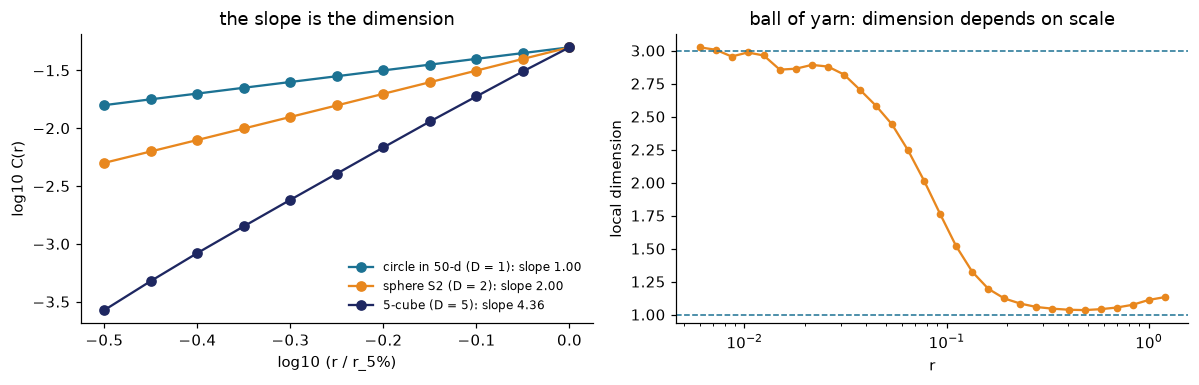

In [27]:
# GIVEN: the pictures
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for (name, X), col in zip(sets.items(), (TEAL, AMBER, NAVY)):
    D = pdist(X); r5 = np.quantile(D, 0.05); rs = r5 * 10 ** np.linspace(-0.5, 0, 11)
    ax[0].plot(np.log10(rs / r5), np.log10([(D <= r).mean() for r in rs]), "o-", color=col, label=f"{name}: slope {slopes[name]:.2f}")
ax[0].set_xlabel("log10 (r / r_5%)"); ax[0].set_ylabel("log10 C(r)"); ax[0].legend(frameon=False, fontsize=8); ax[0].set_title("the slope is the dimension")
ax[1].semilogx(radii, sl, "o-", color=AMBER, ms=4); ax[1].axhline(1, ls="--", color=TEAL, lw=1); ax[1].axhline(3, ls="--", color=TEAL, lw=1)
ax[1].set_xlabel("r"); ax[1].set_ylabel("local dimension"); ax[1].set_title("ball of yarn: dimension depends on scale")
plt.tight_layout(); plt.show()


*Discuss:* the 5-cube gives a slope below 5. Two reasons were mentioned in the lecture (boundary and sample size). Add noise in all coordinates to the circle in 50 dimensions: what happens to the slope at small $r$?

---
### That is the whole lab.

If time remains, your instructor may show an *audit of a claim*: collect a statement about t-SNE or UMAP from any source, and test it with the tools you just built.


---
---
## INSTRUCTOR-ONLY MATERIAL BELOW

Not in the student notebook; a live demonstration, nothing here is graded.

### Bonus — audit a claim

**Claim to test:** "UMAP preserves global structure better than t-SNE", and the related folklore that the initialisation matters. The *global score* below is the Spearman correlation between pairwise distances in the data and in the picture (20 000 random pairs). The first 600 handwritten digits are used. Run it, look at the numbers, and discuss what a single run and a single data set can and cannot show.


In [28]:
from scipy.stats import spearmanr
from sklearn.datasets import load_digits

Xd = load_digits().data.astype(float)[:600]

def global_score(X, Y, m=20000, seed=0):
    rng = np.random.default_rng(seed)
    i, j = rng.integers(len(X), size=m), rng.integers(len(X), size=m); keep = i != j
    return float(spearmanr(np.linalg.norm(X[i[keep]] - X[j[keep]], axis=1), np.linalg.norm(Y[i[keep]] - Y[j[keep]], axis=1))[0])

claims = {
    "PCA": PCA(2).fit_transform(Xd),
    "t-SNE, PCA initialisation": TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(Xd),
    "t-SNE, random initialisation": TSNE(2, perplexity=30, init="random", random_state=0).fit_transform(Xd),
    "UMAP, spectral initialisation": umap.UMAP(n_neighbors=15, init="spectral", random_state=0).fit_transform(Xd),
    "UMAP, random initialisation": umap.UMAP(n_neighbors=15, init="random", random_state=0).fit_transform(Xd),
}
print(f"{'method':32s} global score   T     C")
for name, Y in claims.items():
    print(f"{name:32s} {global_score(Xd, Y):8.3f}    {sk_trustworthiness(Xd, Y, n_neighbors=10):.3f} {sk_trustworthiness(Y, Xd, n_neighbors=10):.3f}")


method                           global score   T     C
PCA                                 0.602    0.837 0.950
t-SNE, PCA initialisation           0.492    0.992 0.988
t-SNE, random initialisation        0.488    0.992 0.987
UMAP, spectral initialisation       0.357    0.986 0.984
UMAP, random initialisation         0.350    0.987 0.984


One data set, one seed, 600 points. The right next steps: repeat over seeds, over data sets (the sphere, the Swiss roll), and over parameters, and decide what *claim* the evidence supports. A claim that holds in one cell of that grid and fails in the next is the same lesson as in Exercise 4.